In [50]:
import pandas as pd
import numpy as np

In [53]:
df = pd.read_csv("./dataset/LeesmateriaalCSV.csv", sep=";")

In [54]:
# Controleren of Themas_boek en trefwoorden per rij identiek zijn
df["Themas_boek"] = (
    df["Themas_boek"]
    .astype("string")
    .fillna("")
    .str.replace(r"(?:https?://|www\.)\S+(?:\s+\[[^\]]+\])?", "", regex=True, case=False)
    .str.replace(r"\[[^\]]+\]", "", regex=True)
    .str.strip(" ,;")
)
themas_boek = df["Themas_boek"].astype("string").fillna("").map(
    lambda waarde: ";".join(woord.strip() for woord in waarde.split(";"))
)
trefwoorden = df["trefwoorden"].astype("string").fillna("").map(
    lambda waarde: ";".join(woord.strip() for woord in waarde.split(";"))
)
zelfde = themas_boek.eq(trefwoorden)
verschillen = df.loc[~zelfde, ["Titel", "Themas_boek", "trefwoorden"]]

print(f"Alle waarden identiek: {verschillen.empty}")
verschillen

Alle waarden identiek: False


,Titel,Themas_boek,trefwoorden
154,De wondere wereld van nachtvlinders,,[naturetoday.com]
155,Boeren geven de zwarte stern vleugels in de Ut...,,[naturetoday.com]
188,Zolang het tuin duurt 2,"zelfreflectie,doorzetten",zelfreflectie; doorzetten
201,De kleine kust,"jongeren,vriendschap",jongeren; vriendschap
231,Wat Joris niet wist,"doorzetten,liefde",doorzetten; liefde
242,Sleutel zonder kust,liefde/samenleving,liefde; samenleving
246,De brief van Jelle,geheimen|macht,geheimen; macht
254,Een foto voor Sem,"veerkracht,oorlog",veerkracht; oorlog
270,Het witte huis,reizen/oorlog,reizen; oorlog
282,Grens in de haven,"doorzetten,stalking",doorzetten; stalking


In [55]:
# Controleren of elk onderwerp in de trefwoorden voorkomt
onderwerpen = df["onderwerp"].astype("string").fillna("").str.strip().str.casefold()
trefwoorden = [
    [woord.strip().casefold() for woord in rij.split(";") if woord.strip()]
    for rij in df["trefwoorden"].astype("string").fillna("")
]
onderwerp_gevonden = pd.Series(
    [
        bool(onderwerp) and onderwerp in woorden
        for onderwerp, woorden in zip(onderwerpen, trefwoorden)
    ],
    index=df.index,
)
ontbreekt = df.loc[
    onderwerpen.ne("") & ~onderwerp_gevonden,
    ["Titel", "onderwerp", "trefwoorden"],
]
print(f"Alle onderwerpen staan in trefwoorden: {ontbreekt.empty}")
ontbreekt

Alle onderwerpen staan in trefwoorden: True


,Titel,onderwerp,trefwoorden


In [5]:
# Controleren of ingevulde genres_kopie al in genre staan
genre = df["genre"].astype("string").fillna("").str.strip().str.casefold()
genre_kopie = df["genre_kopie"].astype("string").fillna("").str.strip().str.casefold()
extra_genres = genre_kopie.ne("") & genre_kopie.ne(genre)
verschillen_genre = df.loc[extra_genres, ["Titel", "genre", "genre_kopie"]]

print(f"Alle ingevulde genres_kopie komen overeen met genre: {verschillen_genre.empty}")
verschillen_genre

Alle ingevulde genres_kopie komen overeen met genre: True


,Titel,genre,genre_kopie


In [ ]:
#onnodige kolommen verwijderen
df = df.drop(columns=['Unnamed: 3', 'Themas_boek', 'materiaal_id', 'interne_batchcode', 'genre_kopie', 'woordenaantal_omschrijving', 'aandeel_lange_woorden_pct', 'aantal_zinnen', 'administratieve_prioriteit'])

In [5]:
# Genre uit Type materiaal verplaatsen als genre leeg is
mask = df["Type materiaal"].str.match(r"(?i)^boek\s*-", na=False)
genre = df.loc[mask, "Type materiaal"].str.split("-", n=1).str[1].str.strip()
missing_genre = df["genre"].isna()
df.loc[mask & missing_genre, "genre"] = genre.loc[mask & missing_genre]

In [6]:
#Type materiaal normaliseren
mask = df["Type materiaal"].str.match(r"(?i)^boek\s*-", na=False)
df.loc[mask, "Type materiaal"] = "boek"
df.loc[df["Type materiaal"] == "Boek", "Type materiaal"] = "boek"
df.loc[df["Type materiaal"] == "digitale krant", "Type materiaal"] = "krant (digitaal)"

In [7]:
#Taal normaliseren
df["taal"] = "NL"

In [8]:
#Doelgroep normaliseren
df.loc[df["doelgroep"] == "mbo", "doelgroep"] = "MBO"
df.loc[df["doelgroep"] == "mbo / nt2", "doelgroep"] = "MBO/NT2"

In [9]:
#Doelgroepen combineren
def combineer_doelgroepen(row):
    groepen = []

    for waarde in row.dropna():
        for groep in str(waarde).split("/"):
            groep = groep.strip()

            if groep != "" and groep not in groepen:
                groepen.append(groep)

    volgorde = {"MBO": 0, "NT2": 1}
    groepen.sort(key=lambda groep: volgorde.get(groep, 2))

    return "/".join(groepen)

df["doelgroep"] = df[["doelgroep", "doelgroep_extra"]].apply(
    combineer_doelgroepen, axis=1
)
df.loc[df["doelgroep"] == "", "doelgroep"] = np.nan

df = df.drop(["doelgroep_extra"], axis=1)

In [10]:
#onrealistische waarden in gem_woordlengte vervangen door NaN
df.loc[df["gem_woordlengte"] > 10, ["gem_woordlengte"]] = np.nan

In [11]:
#interessecluster normaliseren
df["interessecluster"] = df["interessecluster"].str.lower()

In [12]:
#onrealistische en onbekende jaartallen in publicatiejaar vervangen door 'onbekend'
df.loc[df["publicatiejaar"] == 'onbekend', ["publicatiejaar"]] = np.nan
df["publicatiejaar"] = df["publicatiejaar"].astype("Int64")
df.loc[df["publicatiejaar"] > 2026, ["publicatiejaar"]] = np.nan

In [13]:
#beschikbaar_formaat normaliseren
df["beschikbaar_formaat"] = df["beschikbaar_formaat"].str.lower()

In [14]:
#aantal_paginas normaliseren
df.loc[df["aantal_paginas"] < 1, "aantal_paginas"] = np.nan
df["aantal_paginas"] = df["aantal_paginas"].astype('Int64')

In [15]:
#geschatte_leestijd_min normaliseren
df.loc[df["geschatte_leestijd_min"] < 1, "geschatte_leestijd_min"] = np.nan

In [17]:
#Gegevensstatus opschonen en veranderen naar bruikbare data
df.loc[df["gegevensstatus"] == "Aangevuld (deels gesimuleerd)", ["gegevensstatus"]] = 'Beschikbaar'
df.loc[df["gegevensstatus"] == "gecontroleerd", ["gegevensstatus"]] = 'Binnenkort Terug Verwacht'
df.loc[df["gegevensstatus"] == "In behandeling", ["gegevensstatus"]] = 'Uitgeleend'
df.loc[df["gegevensstatus"].isna(), ["gegevensstatus"]] = 'Onbekend'

In [18]:
# Korte url-vermelding uit bron_url verwijderen
df["bron_url"] = df["bron_url"].str.replace(
    r"((?:https?://|www\.)\S+?)(?:\s*,?\s*\[[^\]]+\])+",
    r"\1",
    regex=True,
)

In [ ]:
# Auteurs scheiden met een slash
df["Auteur"] = (
    df["Auteur"]
    .str.replace(r"\s+en\s+", ";", case=False, regex=True)
    .str.replace(r"\s*[,&]\s*", ";", regex=True)
    .str.replace(r"\s*/\s*", ";", regex=True)
    .str.strip()
)

In [20]:
df["trefwoorden"] = df["trefwoorden"].str.replace("; ", ";")

In [ ]:
ag = df[df["aantal_paginas"].notna() & df["geschatte_leestijd_min"].notna()][["aantal_paginas", "geschatte_leestijd_min"]]


,aantal_paginas,geschatte_leestijd_min
0,265.0,556.0
1,171.0,184.0
2,219.0,662.0
3,288.0,748.0
4,358.0,196.0
...,...,...
278,3.0,14.0
279,6.0,19.0
280,145.0,245.0
281,255.0,346.0


In [79]:
df[df["aantal_paginas"].isna() | df["geschatte_leestijd_min"].isna()]

,Titel,Auteur,Korte omschrijving,Unnamed: 3,Type materiaal,Niveau,Themas_boek,materiaal_id,genre,onderwerp,...,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,interne_batchcode,administratieve_prioriteit,doelgroep_extra,genre_kopie,Gemiddelde beoordeling,Nieuwe Rij


In [ ]:
gem_paginas_p_min = ag["aantal_paginas"].mean() / ag["geschatte_leestijd_min"].mean()
gem_min_p_p = ag["geschatte_leestijd_min"].mean() / ag["aantal_paginas"].mean()

df.loc[df["aantal_paginas"].isna() & df["geschatte_leestijd_min"].notna(), "aantal_paginas"] = df["geschatte_leestijd_min"] * gem_paginas_p_min
df.loc[df["geschatte_leestijd_min"].isna() & df["aantal_paginas"].notna(), "geschatte_leestijd_min"] = df["aantal_paginas"] * gem_min_p_p

0.47938052447809076 2.0860255036199393


In [ ]:
def create_new_row(df):
    kolommen = ["Korte omschrijving", "genre", "onderwerp", "trefwoorden", "Niveau", "uitgever", "beschikbaar_formaat"]
    delen = df[kolommen].fillna("").astype("string")
    df["Gecombineerd"] = delen.apply(
        lambda rij: "/".join(deel for deel in rij if deel.strip()),
        axis=1,
    )
    return df

In [66]:
df = create_new_row(df)

In [82]:
df[df["gem_zinslengte_woorden"] < 0]

,Titel,Auteur,Korte omschrijving,Unnamed: 3,Type materiaal,Niveau,Themas_boek,materiaal_id,genre,onderwerp,...,uitgever,publicatiejaar,beschikbaar_formaat,cataloguscode,interne_batchcode,administratieve_prioriteit,doelgroep_extra,genre_kopie,Gemiddelde beoordeling,Nieuwe Rij


In [23]:
# aantal unieke en missende waarden en datatypes
print("Aantal rijen en kolommen:", df.shape)
overzicht = pd.DataFrame({
    "Aantal unieke waarden": df.nunique(),
    "Aantal missende waarden": df.isna().sum(),
    "Datatype": df.dtypes,
    "Aantal dubbele waarden": df.apply(
        lambda kolom: kolom.dropna().duplicated().sum()
    )
})
 
display(overzicht)

Aantal rijen en kolommen: (283, 22)


,Aantal unieke waarden,Aantal missende waarden,Datatype,Aantal dubbele waarden
Titel,277,0,str,6
Auteur,231,7,str,45
Korte omschrijving,282,0,str,1
Type materiaal,7,0,str,276
Niveau,4,6,str,273
genre,5,15,str,263
trefwoorden,93,181,str,9
taal,1,0,str,282
aantal_paginas,157,28,Int64,98
geschatte_leestijd_min,212,9,float64,62


## Dimensionality reduction op de opgeschoonde data (PCA, t-SNE, UMAP)

**Wat gaan we doen?**
Elk boek heeft 5 cijfers (pagina's, leestijd, woordlengte, zinslengte en leescomplexiteit). Dat zijn te veel cijfers om in één plaatje te zetten. Met PCA, t-SNE en UMAP maken we er een plaatje van met maar 2 richtingen (links/rechts en omhoog/omlaag). Boeken die op elkaar lijken komen dan dicht bij elkaar te staan. Zo zien we of boeken van hetzelfde niveau op elkaar lijken.

**Wat gebeurt er in de code hieronder?**
1. **Features kiezen:** we kiezen de 5 getal-kolommen die we gebruiken om boeken te vergelijken.
2. **Label kiezen:** we kiezen `Niveau` (2F, 3F, 3F+) om de punten later mee te kleuren. Het label gebruiken de technieken zelf niet, het is alleen voor ons om te kijken of boeken van hetzelfde niveau bij elkaar komen te liggen.
3. **Kopie maken zonder lege waardes:** de technieken kunnen niet tegen lege vakjes. Daarom maken we een kopie (`df_analyse`) met alleen de boeken waar alle 5 de cijfers zijn ingevuld. De originele tabel `df` blijft zoals hij was, zodat we de lege waardes later nog kunnen invullen.
4. **Schalen:** leestijd is een groot getal (honderden) en woordlengte een klein getal (rond 6). Zonder schalen telt het grote getal te zwaar mee. Met `StandardScaler` brengen we alle kolommen op dezelfde schaal.
5. **Plotfunctie:** `plot_2d` is een hulpfunctie die een plaatje maakt waarin elk punt een boek is, gekleurd per niveau. Die gebruiken we straks bij alle drie de technieken.

De code print ook hoeveel boeken er meedoen en hoeveel er zijn weggelaten door lege waardes.

In [22]:
# --- Features, labels en schalen ---
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# 1) Welke numerieke kolommen gebruiken we als features, en waarop kleuren we de punten?
features = [
    "aantal_paginas",
    "geschatte_leestijd_min",
    "gem_woordlengte",
    "gem_zinslengte_woorden",
    "leescomplexiteit_score",
]
label_kolom = "Niveau"

# 2) Kopie met alleen volledige rijen (df zelf blijft ongemoeid)
# LET OP: na feature engineering vervang je hier df door de ingevulde dataframe
# en laat je (indien alles is ingevuld) .dropna() alleen nog voor het label staan.
df_analyse = df[features + [label_kolom]].dropna().copy()
df_analyse[features] = df_analyse[features].astype(float)  # Int64 -> float

X = df_analyse[features].to_numpy()
y = df_analyse[label_kolom].to_numpy()   # labels (2F, 2F-3F, 3F, 3F+) om punten te kleuren

# 3) Schalen (gemiddelde 0, std 1): leestijd loopt in honderden, woordlengte rond 6
X_scaled = StandardScaler().fit_transform(X)

print(f"Rijen in df: {len(df)} | rijen in analyse: {len(df_analyse)} "
      f"({len(df) - len(df_analyse)} weggelaten door lege waardes)")
print("X_scaled shape:", X_scaled.shape)
print(df_analyse[label_kolom].value_counts())


def plot_2d(X_2d, titel, xlabel, ylabel):
    """Scatterplot per label (Niveau) met legenda."""
    plt.figure(figsize=(7, 5))
    for label in sorted(np.unique(y)):
        m = y == label
        plt.scatter(X_2d[m, 0], X_2d[m, 1], s=40, alpha=0.8, label=label)
    plt.title(titel)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.legend(title=label_kolom)
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.show()

Rijen in df: 283 | rijen in analyse: 207 (76 weggelaten door lege waardes)
X_scaled shape: (207, 5)
Niveau
2F       102
3F        68
3F+       23
2F-3F     14
Name: count, dtype: int64


### PCA

**Wat doet PCA?**
PCA zoekt de "beste hoek" om naar je boeken te kijken. Het maakt van de 5 cijfers per boek 2 nieuwe cijfers (5D -> 2D), zodat je een plaatje kunt maken. Het kiest die 2 nieuwe cijfers zo, dat je zoveel mogelijk van de verschillen tussen de boeken blijft zien. Het is net als een foto van een 3D-voorwerp: je kiest de hoek waarop je het meeste ziet.

**Wat gebeurt er in de code hieronder?**
1. **PCA uitvoeren:** we vragen om 2 nieuwe assen, PC1 (links/rechts) en PC2 (omhoog/omlaag). PC1 laat de meeste verschillen tussen de boeken zien, PC2 de tweede meeste.
2. **Verklaarde variantie:** de code print hoeveel procent van alle verschillen elke as laat zien. Zijn die twee getallen samen hoog, dan is het plaatje betrouwbaar. Het stuk dat ontbreekt tot 100% is informatie die we kwijt zijn door van 5 naar 2 te gaan.
3. **Loadings:** een tabel die laat zien hoe PC1 en PC2 zijn opgebouwd uit de 5 oorspronkelijke kolommen. Een getal ver van 0 betekent dat die kolom zwaar meetelt voor die as. Een plus en een min betekenen dat de kolommen elkaars tegenpool zijn (de ene hoog, de andere laag). Zo kun je uitleggen wat een as eigenlijk betekent.
4. **Plaatje:** elk punt is een boek, gekleurd per niveau. Punten die dicht bij elkaar liggen zijn boeken die op elkaar lijken.

**Let op:** PCA is de enige van de drie technieken waarbij de assen echt iets betekenen. Bij t-SNE en UMAP zijn de assen alleen een plek op het plaatje.

In [ ]:
# --- PCA: lineaire reductie naar 2D ---
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("Verklaarde variantie ratio (per component):", pca.explained_variance_ratio_)
print("Totaal verklaarde variantie:", pca.explained_variance_ratio_.sum())

# Loadings: welke features wegen zwaar mee in PC1 en PC2?
loadings = pd.DataFrame(pca.components_.T, index=features, columns=["PC1", "PC2"])
display(loadings.round(2))

plot_2d(X_pca, "PCA – 2D projectie", "PC1", "PC2")

Verklaarde variantie ratio (per component): [0.45828974 0.29663563]
Totaal verklaarde variantie: 0.7549253732768769


### t-SNE

**Wat doet t-SNE?**
t-SNE kijkt bij elk boek wie er in de buurt zit: welke boeken lijken het meest op dit boek? Daarna maakt het een plaatje waarin die buren ook echt naast elkaar liggen. Het is net als een klas die in groepjes gaat zitten: wie op elkaar lijkt, zit bij elkaar. Daardoor is t-SNE goed in het zichtbaar maken van groepjes (clusters).

**Wat gebeurt er in de code hieronder?**
1. **t-SNE uitvoeren:** we vragen om 2 nieuwe assen, zodat we een plaatje kunnen maken.
2. **Perplexity = 30:** dit getal bepaalt met hoeveel buren elk boek rekening houdt. Een laag getal kijkt naar heel kleine groepjes, een hoog getal naar grotere groepen. 30 is een gangbare beginwaarde.
3. **random_state = 42:** t-SNE gebruikt een beetje toeval. Met dit getal krijg je elke keer hetzelfde plaatje als je de cel opnieuw draait.
4. **Plaatje:** elk punt is een boek, gekleurd per niveau.

**Hoe lees je het plaatje?**
- Punten die dicht bij elkaar liggen, zijn boeken die op elkaar lijken. Dat mag je gebruiken.
- Een los groepje betekent dat die boeken op elkaar lijken en anders zijn dan de rest.
- De assen betekenen niets, het zijn alleen plekken op het plaatje. Ze hebben dus geen echte naam, daarom heten ze "Dim 1" en "Dim 2".
- De afstand tussen twee groepjes zegt niets. Een groepje dat ver weg ligt, is dus niet per se "anderder" dan een groepje dat dichtbij ligt.
- Er is geen "verklaarde variantie" zoals bij PCA, want t-SNE meet geen verschillen op één as.

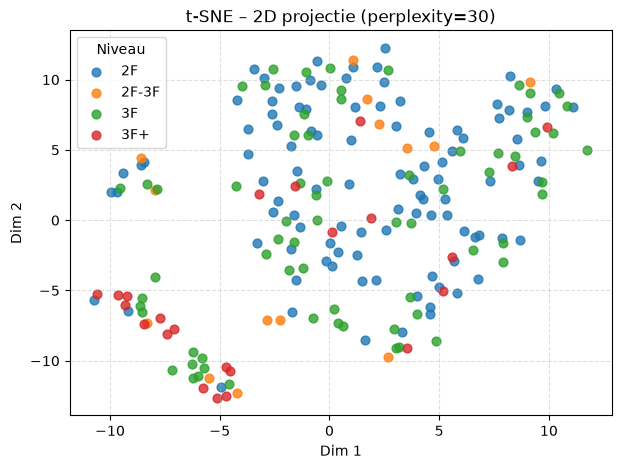

In [27]:
# --- t-SNE: focust op lokale structuur / clustervorming ---
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

plot_2d(X_tsne, "t-SNE – 2D projectie (perplexity=30)", "Dim 1", "Dim 2")

### UMAP

**Wat doet UMAP?**
UMAP werkt een beetje zoals t-SNE: het kijkt bij elk boek wie er in de buurt zit en zet die buren in het plaatje bij elkaar. Het verschil is dat UMAP ook een beetje let op het grote geheel. Groepjes die in het echt dicht bij elkaar zitten, komen daardoor vaker ook op het plaatje dicht bij elkaar te liggen. UMAP is ook meestal sneller dan t-SNE.

**Wat gebeurt er in de code hieronder?**
1. **UMAP uitvoeren:** we vragen om 2 nieuwe assen, zodat we een plaatje kunnen maken.
2. **n_neighbors = 15:** met hoeveel buren houdt elk boek rekening? Een laag getal kijkt naar kleine groepjes, een hoog getal naar grotere groepen. 15 is een gangbare beginwaarde.
3. **min_dist = 0.1:** hoe dicht mogen punten in een groepje op elkaar zitten? Een laag getal geeft strakke, dichte groepjes. Een hoger getal spreidt de punten meer uit.
4. **random_state = 42:** UMAP gebruikt een beetje toeval. Met dit getal krijg je elke keer hetzelfde plaatje.
5. **Plaatje:** elk punt is een boek, gekleurd per niveau.

**Hoe lees je het plaatje?**
- Punten die dicht bij elkaar liggen, zijn boeken die op elkaar lijken.
- Een los groepje betekent dat die boeken op elkaar lijken en anders zijn dan de rest.
- De assen betekenen niets, net als bij t-SNE. Daarom heten ze "Dim 1" en "Dim 2".
- De afstand tussen groepjes zegt bij UMAP iets meer dan bij t-SNE, maar lees er niet te veel in.

**Eenmalig nodig:** staat UMAP nog niet op je computer? Verwijder het hekje voor `!pip install umap-learn`, draai die regel één keer en zet het hekje weer terug. Krijg je een waarschuwing (`UserWarning`) over `n_jobs`? Die is onschuldig: hij komt doordat we `random_state` hebben ingesteld.

/opt/anaconda3/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


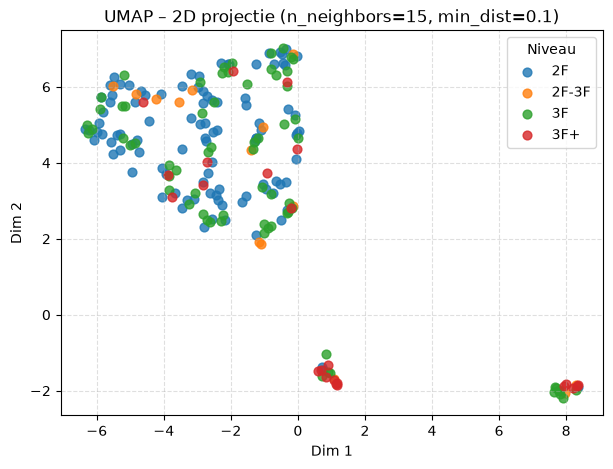

In [28]:
# --- UMAP: snel en behoudt lokale + deels globale structuur ---
import umap

umap_model = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
X_umap = umap_model.fit_transform(X_scaled)

plot_2d(X_umap, "UMAP – 2D projectie (n_neighbors=15, min_dist=0.1)", "Dim 1", "Dim 2")